In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [20]:
df = pd.read_csv("/content/smartcart_dataset.csv")

print("Shape:", df.shape)
print(df["category"].value_counts())
df.head()

Shape: (1200, 6)
category
Apparel        400
Electronics    400
Grocery        400
Name: count, dtype: int64


,price,weight_kg,rating,discount_pct,description_length,category
0,438.29,3.413,4.1,57.5,47,Apparel
1,719.57,6.111,3.5,46.5,45,Apparel
2,1202.48,9.337,4.1,23.7,109,Electronics
3,316.98,2.752,4.4,21.9,20,Grocery
4,2037.38,6.407,3.6,14.1,93,Electronics


<Axes: xlabel='price', ylabel='weight_kg'>

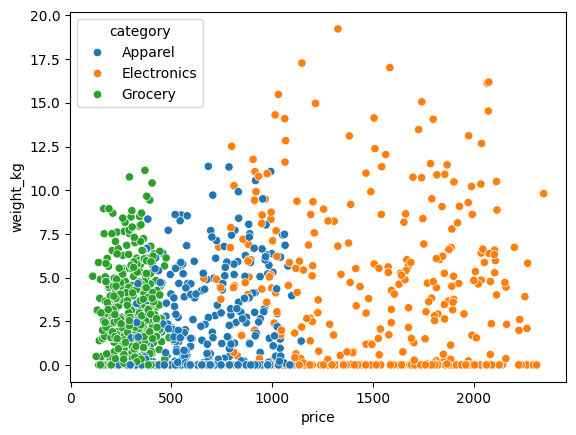

In [21]:
sns.scatterplot(data=df, x='price', y='weight_kg', hue='category')

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

FEATURES = ['price', 'weight_kg', 'rating', 'discount_pct', 'description_length']
TARGET = 'category'

X = df[FEATURES]
y_raw = df[TARGET]
le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_
print(dict(zip(range(len(class_names)), class_names)))

{0: 'Apparel', 1: 'Electronics', 2: 'Grocery'}


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train.shape, X_test.shape

((960, 5), (240, 5))

In [24]:
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

perceptron = Sequential()
perceptron.add(Dense(3, activation='softmax', input_dim=X_train.shape[1]))
perceptron.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 3)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18 (72.00 B)

 Trainable params: 18 (72.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:
perceptron.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
history_p = perceptron.fit(X_train, y_train, epochs=100,
                            validation_split=0.2, verbose=0)

In [26]:
weights, bias = perceptron.layers[0].get_weights()
print('weights:\n', weights)
print('bias:\n', bias)

weights:
 [[-0.38440287  1.2049195  -1.399289  ]
 [-0.11764265  0.32458633  0.26919287]
 [-0.5323856   0.12289752 -0.39890167]
 [ 1.29975     0.21147832 -0.36267996]
 [ 0.09970777  0.9739346  -0.46789682]]
bias:
 [ 0.36880717 -0.01928901 -0.41771394]


In [27]:
perceptron_loss, perceptron_acc = perceptron.evaluate(X_test, y_test, verbose=0)
print(f'Perceptron test accuracy: {perceptron_acc:.3f}')

Perceptron test accuracy: 0.892


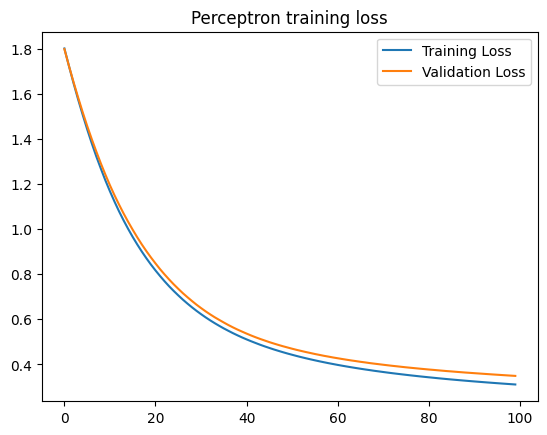

In [28]:
plt.plot(history_p.history['loss'], label='Training Loss')
plt.plot(history_p.history['val_loss'], label='Validation Loss')
plt.title('Perceptron training loss')
plt.legend()
plt.show()

In [29]:
ann = Sequential()
ann.add(Dense(32, activation='relu', input_dim=X_train.shape[1]))
ann.add(Dense(16, activation='relu'))
ann.add(Dense(3, activation='softmax'))

ann.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
ann.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
history_ann = ann.fit(X_train, y_train, epochs=100,
                       validation_split=0.2, verbose=0)
ann_loss, ann_acc = ann.evaluate(X_test, y_test, verbose=0)
print(f'ANN test accuracy: {ann_acc:.3f}')

ANN test accuracy: 0.925


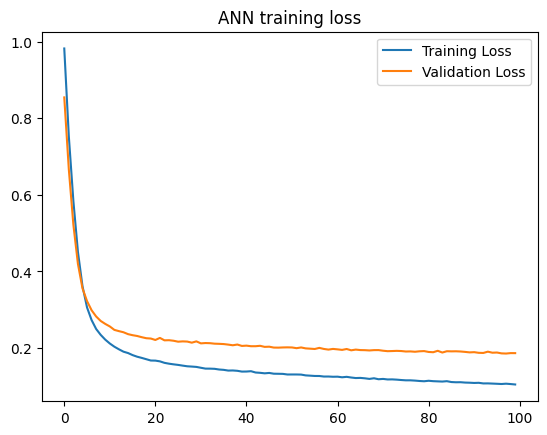

In [31]:
plt.plot(history_ann.history['loss'],
label='Training Loss')
plt.plot(history_ann.history['val_loss'],
label='Validation Loss')
plt.title('ANN training loss')
plt.legend()
plt.show()

In [34]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Step 1: Create Logistic Regression model
logreg = LogisticRegression(max_iter=1000)

# Step 2: Train the model
logreg.fit(X_train, y_train)

# Step 3: Predict test data
y_pred_logreg = logreg.predict(X_test)

# Step 4: Calculate accuracy
logreg_acc = accuracy_score(y_test, y_pred_logreg)

print("Logistic Regression Test Accuracy:", round(logreg_acc, 3))

# Step 5: Classification report
print(classification_report(y_test, y_pred_logreg))


Logistic Regression Test Accuracy: 0.925
              precision    recall  f1-score   support

           0       0.92      0.85      0.88        80
           1       0.94      0.95      0.94        80
           2       0.92      0.97      0.95        80

    accuracy                           0.93       240
   macro avg       0.92      0.92      0.92       240
weighted avg       0.92      0.93      0.92       240



In [35]:
log_reg = LogisticRegression(max_iter=2000)
log_reg.fit(X_train_scaled, y_train)
y_pred_logreg = log_reg.predict(X_test_scaled)
logreg_acc = accuracy_score(y_test, y_pred_logreg)

print(f"Logistic Regression test accuracy: {logreg_acc:.3f}\n")
print(classification_report(y_test, y_pred_logreg, target_names=class_names))

Logistic Regression test accuracy: 0.925

              precision    recall  f1-score   support

     Apparel       0.92      0.85      0.88        80
 Electronics       0.94      0.95      0.94        80
     Grocery       0.92      0.97      0.95        80

    accuracy                           0.93       240
   macro avg       0.92      0.92      0.92       240
weighted avg       0.92      0.93      0.92       240



In [36]:
y_pred_perceptron = perceptron.predict(X_test_scaled)

y_pred_ann = ann.predict(X_test_scaled)

# Convert probabilities into class labels
y_pred_ann = (y_pred_ann > 0.5).astype(int).ravel()

y_pred_logreg = log_reg.predict(X_test_scaled)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


In [37]:
import numpy as np

y_pred_perceptron = perceptron.predict(X_test_scaled)

# ANN predictions
ann_output = ann.predict(X_test_scaled)

# Convert probabilities into class labels
y_pred_ann = np.argmax(ann_output, axis=1)

# Logistic Regression predictions
y_pred_logreg = log_reg.predict(X_test_scaled)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [38]:
import numpy as np

# Convert Perceptron output into class labels
y_pred_perceptron = np.argmax(y_pred_perceptron, axis=1)

print("Perceptron shape:", y_pred_perceptron.shape)

Perceptron shape: (240,)


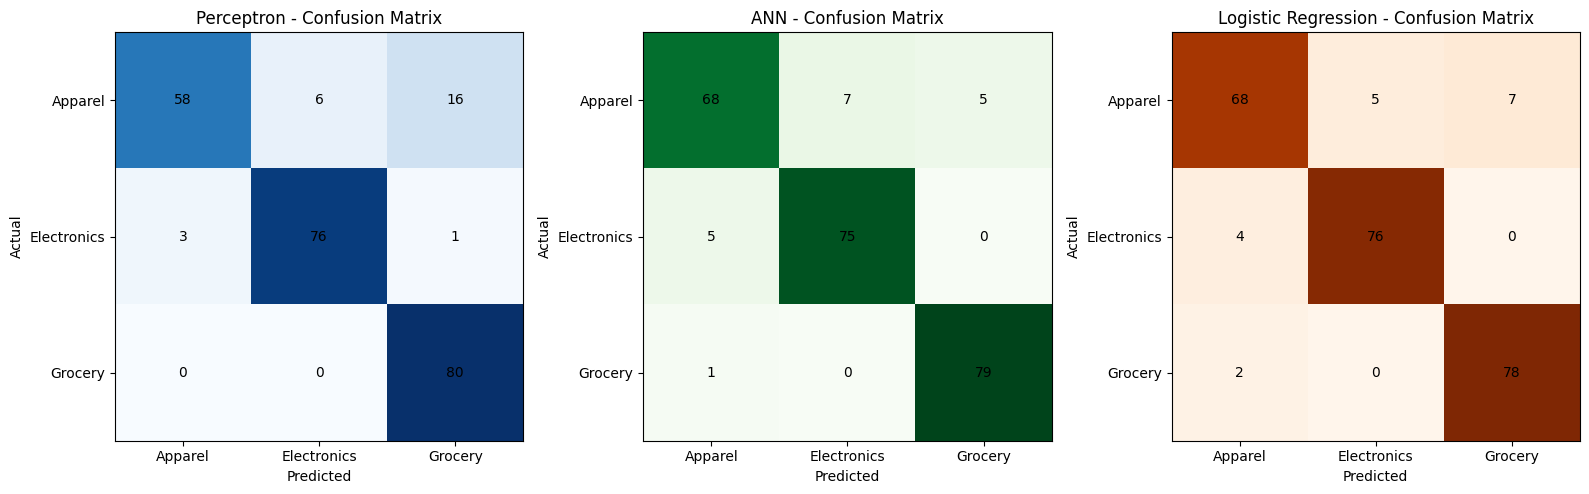

In [40]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, y_pred, title, cmap in zip(
    axes,
    [y_pred_perceptron, y_pred_ann, y_pred_logreg],
    ['Perceptron - Confusion Matrix',
     'ANN - Confusion Matrix',
     'Logistic Regression - Confusion Matrix'],
    ['Blues', 'Greens', 'Oranges']
):
    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Display confusion matrix
    im = ax.imshow(cm, cmap=cmap)

    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names)

    ax.set_yticks(range(len(class_names)))
    ax.set_yticklabels(class_names)

    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(title)

    # Display values inside the matrix
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, cm[i, j],
                    ha='center', va='center')

plt.tight_layout()
plt.show()


In [41]:
print("Actual:", np.array(y_test).shape)
print("Perceptron:", np.array(y_pred_perceptron).shape)
print("ANN:", np.array(y_pred_ann).shape)
print("Logistic:", np.array(y_pred_logreg).shape)

Actual: (240,)
Perceptron: (240,)
ANN: (240,)
Logistic: (240,)


In [42]:
comparison = pd.DataFrame({
    'Model': ['Perceptron (Keras)', 'Logistic Regression (sklearn)',
              'ANN (Keras)'],
    'Test Accuracy': [perceptron_acc,logreg_acc ,ann_acc ]})
comparison

,Model,Test Accuracy
0,Perceptron (Keras),0.891667
1,Logistic Regression (sklearn),0.925000
2,ANN (Keras),0.925000
